# TP2 — Clasificación de Géneros Musicales (Spotify)
### Tecnología Digital VI: Inteligencia Artificial — UTDT

**Integrantes:** 

Luciano Jacofsky

Ian Van Leeuwen

Facundo Guledjian


## 0. Setup e imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    GridSearchCV, RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

## 1. Carga de datos

In [8]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("train:", train.shape)
print("test :", test.shape)
train.head()

train: (4200, 17)
test : (1800, 16)


,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,Expected,Id
0,0,143733,False,0.439,0.196,0,-16.093,1,0.0601,0.88000,0.0000,0.0513,0.525,129.581,4,jazz,4271
1,0,261562,False,0.627,0.876,11,-4.391,0,0.0324,0.01590,0.0000,0.0665,0.418,111.950,4,electronic,2078
2,63,190131,False,0.767,0.869,2,-3.381,0,0.0908,0.14000,0.0000,0.2210,0.751,98.208,4,hip-hop,4921
3,48,201440,False,0.374,0.183,9,-13.225,1,0.0281,0.89700,0.0387,0.1090,0.134,82.042,4,acoustic,4206
4,0,168552,True,0.423,0.721,0,-8.070,1,0.1650,0.00792,0.0000,0.3800,0.382,161.926,4,rock,2423


## 2. Análisis Exploratorio de Datos (EDA)

Antes de modelar queremos entender el dataset, detectar problemas de calidad y ver qué features separan mejor a los géneros.

In [4]:
train.info()
print()
print("Nulos por columna:")
print(train.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   popularity        4200 non-null   int64  
 1   duration_ms       4200 non-null   int64  
 2   explicit          4200 non-null   bool   
 3   danceability      4200 non-null   float64
 4   energy            4200 non-null   float64
 5   key               4200 non-null   int64  
 6   loudness          4200 non-null   float64
 7   mode              4200 non-null   int64  
 8   speechiness       4200 non-null   float64
 9   acousticness      4200 non-null   float64
 10  instrumentalness  4200 non-null   float64
 11  liveness          4200 non-null   float64
 12  valence           4200 non-null   float64
 13  tempo             4200 non-null   float64
 14  time_signature    4200 non-null   int64  
 15  Expected          4200 non-null   str    
 16  Id                4200 non-null   int64  
dtypes: boo

No hay valores nulos, asi que no hace falta imputar. Revisamos el balance de clases, que es importante porque F1-Macro promedia el F1 de cada clase sin ponderar por frecuencia.

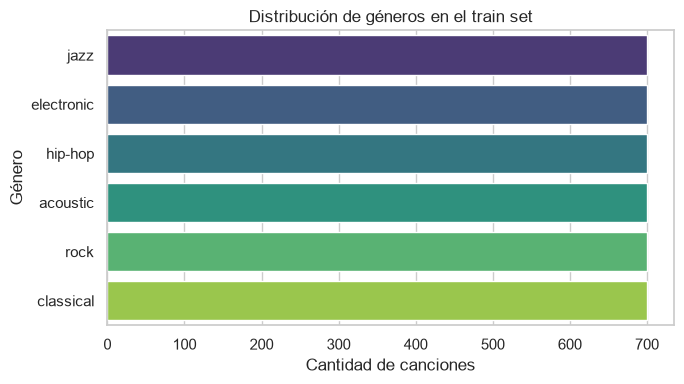

Expected
jazz          700
electronic    700
hip-hop       700
acoustic      700
rock          700
classical     700
Name: count, dtype: int64

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
order = train["Expected"].value_counts().index
sns.countplot(data=train, y="Expected", order=order, hue="Expected",
              palette="viridis", legend=False, ax=ax)
ax.set_title("Distribución de géneros en el train set")
ax.set_xlabel("Cantidad de canciones")
ax.set_ylabel("Género")
plt.tight_layout()
plt.show()

train["Expected"].value_counts()

Las 6 clases están perfectamente balanceadas (700 canciones cada una), por lo que no necesitamos técnicas de balanceo como oversampling o class_weight.

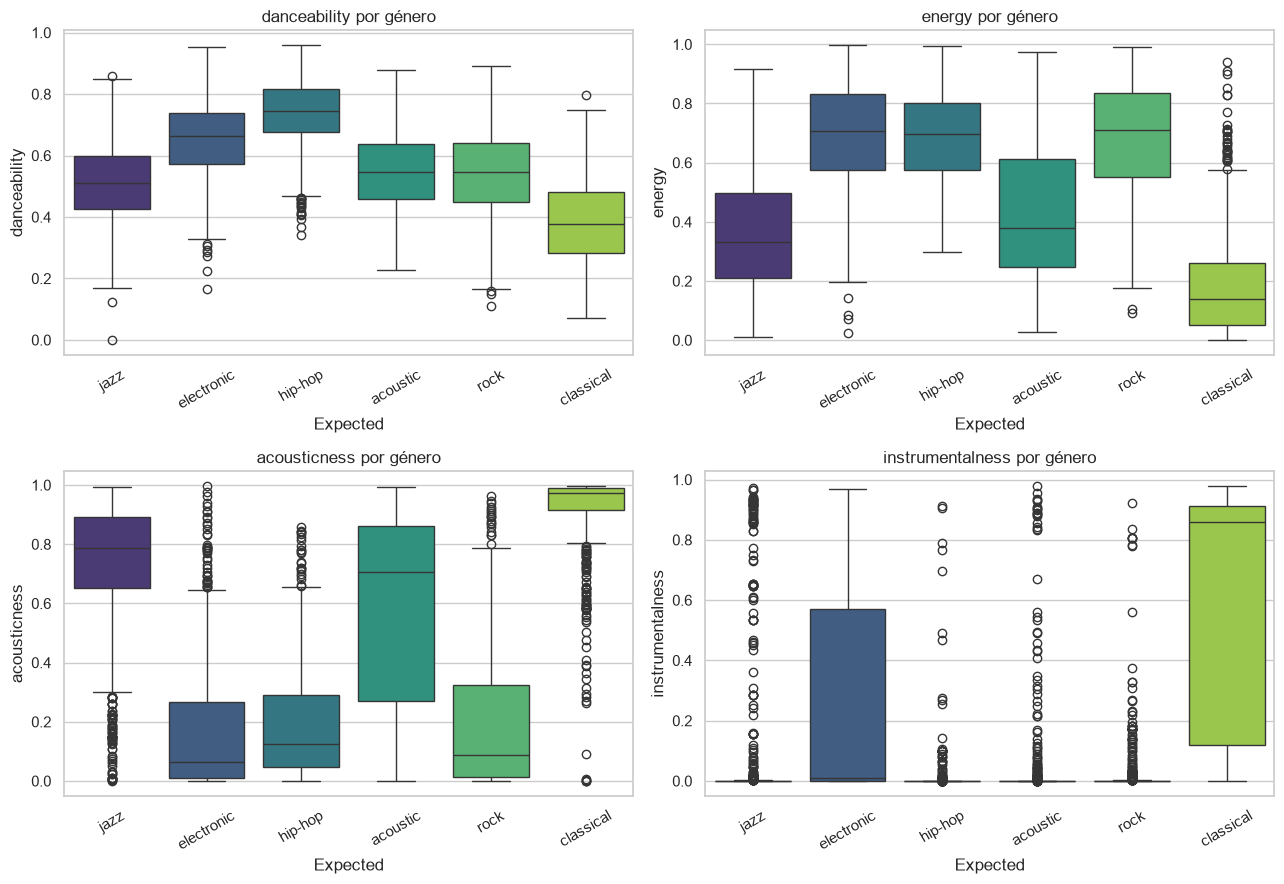

In [6]:
feat_to_plot = ["danceability", "energy", "acousticness", "instrumentalness"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, feat in zip(axes.ravel(), feat_to_plot):
    sns.boxplot(data=train, x="Expected", y=feat, hue="Expected",
                order=order, palette="viridis", legend=False, ax=ax)
    ax.set_title(f"{feat} por género")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Se ve bastante señal:

- `acousticness` e `instrumentalness` separan muy bien a **classical** (valores altos en ambas) del resto. Jazz y acoustic también tienen acousticness alta.
- `energy` separa los géneros tranquilos (classical, jazz, acoustic) de los intensos (rock, electronic, hip-hop).
- `danceability` es la más alta en **hip-hop** y la mas baja en **classical**.
- `instrumentalness` además distingue algo a **electronic**, que tiene bastante variabilidad en esa feature.

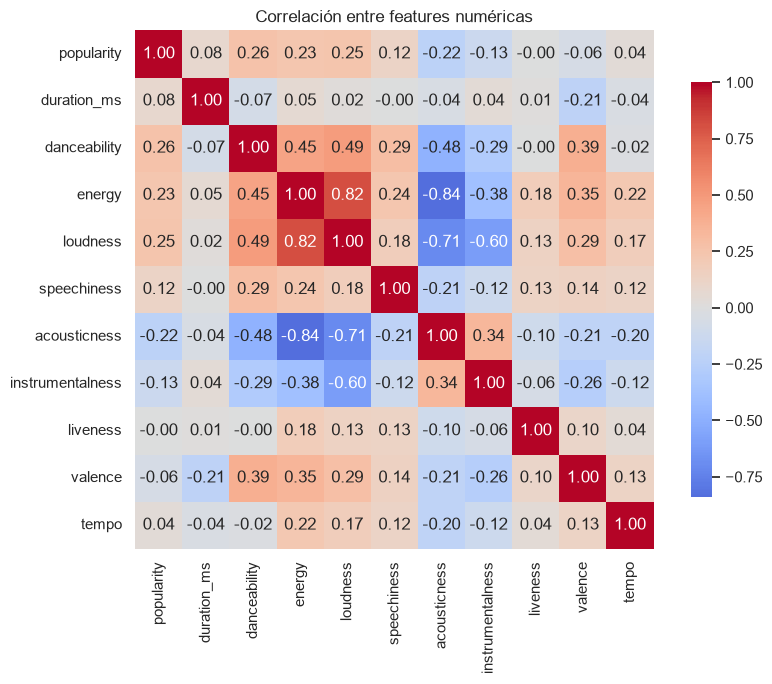

In [7]:
numeric_cols = ["popularity", "duration_ms", "danceability", "energy", "loudness",
                 "speechiness", "acousticness", "instrumentalness", "liveness",
                 "valence", "tempo"]

corr = train[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlación entre features numéricas")
plt.tight_layout()
plt.show()

`energy` y `loudness` están fuertemente correlacionadas (tiene sentido: las canciones con más energía suenan más fuerte), y `energy` con `acousticness` tienen una correlación negativa marcada. Ninguna correlación es tan extrema como para que la multicolinealidad sea un problema serio, aunque puede afectar un poco al modelo lineal.

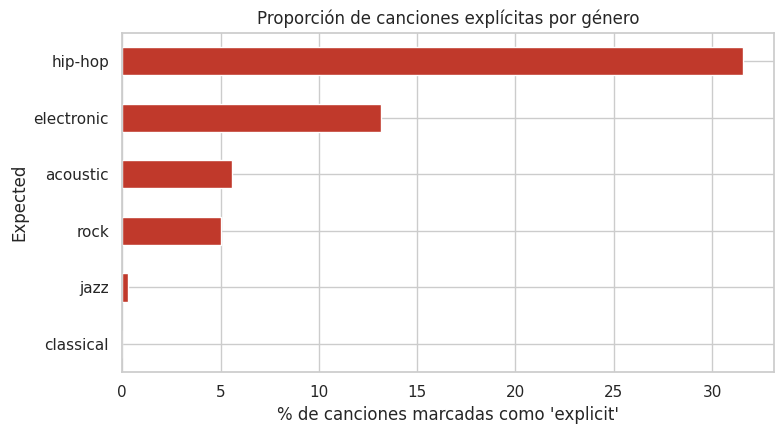

explicit,False,True
Expected,,
acoustic,94.428571,5.571429
classical,100.000000,0.000000
electronic,86.857143,13.142857
hip-hop,68.428571,31.571429
jazz,99.714286,0.285714
rock,95.000000,5.000000


In [7]:
ct = pd.crosstab(train["Expected"], train["explicit"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
ct[True].sort_values().plot(kind="barh", color="#c0392b", ax=ax)
ax.set_xlabel("% de canciones marcadas como 'explicit'")
ax.set_title("Proporción de canciones explícitas por género")
plt.tight_layout()
plt.show()

ct

`explicit` es muy informativo para **hip-hop** (~32% de canciones explícitas, muy por encima del resto) y practicamente nulo para **classical** y **jazz**, así que lo mantenemos como feature.

In [8]:
feat_cols = [c for c in train.columns if c not in ("Id", "Expected")]

dup_mask = train.duplicated(subset=feat_cols, keep=False)
print(f"Filas con exactamente los mismos features que otra fila: {dup_mask.sum()}")

dup_groups = train[dup_mask].groupby(feat_cols)["Expected"].nunique()
conflicting = dup_groups[dup_groups > 1]
n_conflicting_rows = train[dup_mask].groupby(feat_cols).filter(
    lambda g: g["Expected"].nunique() > 1
).shape[0]

print(f"Grupos de duplicados con etiquetas DISTINTAS (mismo audio, distinto género etiquetado): {len(conflicting)}")
print(f"Filas afectadas por esa inconsistencia: {n_conflicting_rows}")

Filas con exactamente los mismos features que otra fila: 938
Grupos de duplicados con etiquetas DISTINTAS (mismo audio, distinto género etiquetado): 17
Filas afectadas por esa inconsistencia: 42


Hay 938 filas que comparten exactamente los mismos features con al menos otra fila, y en 17 grupos (42 filas) **el mismo vector de features tiene géneros distintos**. Esto significa que el dataset tiene un techo de ruido: ningún modelo puede llegar a F1-Macro = 1, porque hay casos que son ambiguos con la información disponible.

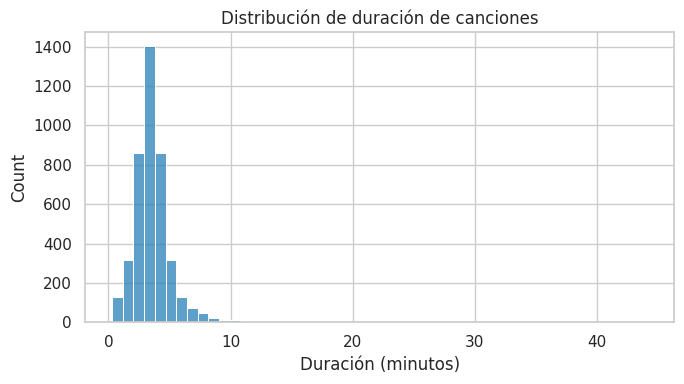

Canciones de más de 10 minutos: 30
      duration_ms   Expected
2529      2646866  classical
3454      1798933  classical
1718      1452106  classical
2227      1371693  classical
248       1341746  classical


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(train["duration_ms"] / 60000, bins=50, ax=ax, color="#2980b9")
ax.set_xlabel("Duración (minutos)")
ax.set_title("Distribución de duración de canciones")
plt.tight_layout()
plt.show()

print("Canciones de más de 10 minutos:", (train['duration_ms'] > 600_000).sum())
print(train.sort_values('duration_ms', ascending=False)[['duration_ms', 'Expected']].head(5))

Hay 30 canciones de más de 10 minutos (la más larga dura unos 44 minutos) y las más largas son todas de **classical**, así que no las tratamos como errores sino como información útil. Los modelos de árboles son robustos a estos outliers porque solo usan el orden de los valores. Para el modelo lineal escalamos las features numéricas.

## 3. Preprocesamiento

### 3.1 Separación Train / Validation

Como `test.csv` no tiene etiquetas, separamos un 20% del train como validation set local para medir F1-Macro y MAP@3 antes de subir a Kaggle. Usamos `stratify=y` para mantener la proporción de géneros en ambas particiones.

Para evitar data leakage, todo el preprocesamiento que aprende de los datos (como el `StandardScaler`) va dentro de un `Pipeline`, así se ajusta solo con el train y después se aplica a validation/test.

In [10]:
TARGET = "Expected"
DROP_COLS = ["Id", TARGET]

X = train.drop(columns=DROP_COLS).copy()
y = train[TARGET].copy()

X["explicit"] = X["explicit"].astype(int)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape, " X_val:", X_val.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_val.value_counts(normalize=True).round(3))

X_train: (3360, 15)  X_val: (840, 15)
Expected
jazz          0.167
acoustic      0.167
electronic    0.167
hip-hop       0.167
rock          0.167
classical     0.167
Name: proportion, dtype: float64
Expected
electronic    0.167
rock          0.167
classical     0.167
jazz          0.167
acoustic      0.167
hip-hop       0.167
Name: proportion, dtype: float64


### 3.2 Tipos de features y ColumnTransformer

Separamos las columnas en tres grupos:

- **Numéricas continuas** (`popularity`, `duration_ms`, `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`): se escalan con `StandardScaler`. Es necesario para la Regresión Logística porque las escalas son muy distintas (`duration_ms` en cientos de miles vs `acousticness` entre 0 y 1), y no perjudica a los modelos de árboles.
- **Categóricas nominales** (`key`, `time_signature`): aunque son números, no tienen un orden real (`key=8` no es "más" que `key=2`), así que usamos `OneHotEncoder`.
- **Binarias** (`mode`, `explicit`): ya son 0/1, pasan sin cambios.

In [11]:
numeric_features = ["popularity", "duration_ms", "danceability", "energy",
                     "loudness", "speechiness", "acousticness",
                     "instrumentalness", "liveness", "valence", "tempo"]
categorical_features = ["key", "time_signature"]
binary_features = ["mode", "explicit"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("bin", "passthrough", binary_features),
])

## 4. Selección de modelos

Implementamos tres modelos:

1. **Regresión Logística**: modelo lineal que usamos como benchmark. Es rápido e interpretable.
2. **Random Forest** (bagging): ensamble de árboles entrenados sobre muestras bootstrap. Captura no linealidades e interacciones entre features.
3. **Histogram Gradient Boosting** (boosting): árboles secuenciales donde cada uno corrige los errores del anterior. Suele ser de lo más competitivo en datos tabulares.

Comparar un modelo lineal contra dos ensambles de árboles nos permite ver qué tipo de hipótesis se ajusta mejor al problema.

In [12]:
models = {
    "LogisticRegression": Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "RandomForest": Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "HistGradientBoosting": Pipeline([
        ("prep", preprocessor),
        ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
}

## 5. Model Selection: Cross-Validation

Evaluar una sola vez sobre `X_val` da una estimación ruidosa, así que comparamos los modelos con **Stratified K-Fold** (5 folds) sobre el train, primero con los hiperparámetros por default.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv,
                              scoring="f1_macro", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:22s} F1-Macro CV: {scores.mean():.4f} (+/- {scores.std():.4f})")

LogisticRegression     F1-Macro CV: 0.6432 (+/- 0.0184)


RandomForest           F1-Macro CV: 0.8070 (+/- 0.0071)


HistGradientBoosting   F1-Macro CV: 0.8166 (+/- 0.0071)


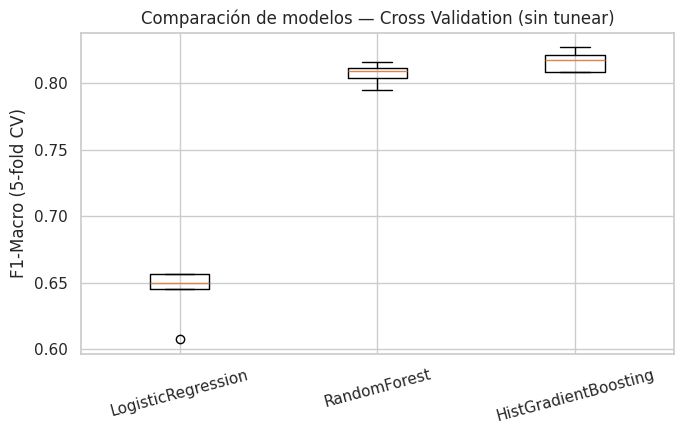

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(cv_results.values(), tick_labels=cv_results.keys())
ax.set_ylabel("F1-Macro (5-fold CV)")
ax.set_title("Comparación de modelos — Cross Validation (sin tunear)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Con hiperparámetros por default los ensambles superan claramente al modelo lineal (≈0.81–0.82 vs ≈0.64 de F1-Macro), lo que indica relaciones no lineales e interacciones entre features que un hiperplano no captura. HistGradientBoosting queda apenas arriba de Random Forest.

## 6. Búsqueda de hiperparámetros

Optimizamos F1-Macro con `GridSearchCV` para la Regresión Logística (pocos hiperparámetros, podemos probar todas las combinaciones) y `RandomizedSearchCV` para los ensambles, donde el espacio es mucho más grande. En todos los casos usamos el mismo `StratifiedKFold` como validación interna.

In [15]:
param_grid_logreg = {
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__solver": ["lbfgs"],
}

gs_logreg = GridSearchCV(
    models["LogisticRegression"], param_grid_logreg,
    scoring="f1_macro", cv=cv, n_jobs=-1, refit=True
)
gs_logreg.fit(X_train, y_train)

print("Mejor F1-Macro (CV):", gs_logreg.best_score_)
print("Mejores hiperparámetros:", gs_logreg.best_params_)

Mejor F1-Macro (CV): 0.6458415810578173
Mejores hiperparámetros: {'clf__C': 100, 'clf__solver': 'lbfgs'}


In [16]:
param_dist_rf = {
    "clf__n_estimators": [200, 300, 500, 800],
    "clf__max_depth": [None, 8, 12, 16, 24],
    "clf__min_samples_leaf": [1, 2, 4, 8],
    "clf__max_features": ["sqrt", "log2", 0.5],
}

rs_rf = RandomizedSearchCV(
    models["RandomForest"], param_dist_rf, n_iter=20,
    scoring="f1_macro", cv=cv, n_jobs=-1,
    random_state=RANDOM_STATE, refit=True
)
rs_rf.fit(X_train, y_train)

print("Mejor F1-Macro (CV):", rs_rf.best_score_)
print("Mejores hiperparámetros:", rs_rf.best_params_)

Mejor F1-Macro (CV): 0.8128895493650548
Mejores hiperparámetros: {'clf__n_estimators': 500, 'clf__min_samples_leaf': 2, 'clf__max_features': 0.5, 'clf__max_depth': 24}


In [17]:
param_dist_hgb = {
    "clf__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "clf__max_iter": [150, 250, 350],
    "clf__max_depth": [None, 4, 6, 10],
    "clf__l2_regularization": [0.0, 0.1, 1.0],
}

rs_hgb = RandomizedSearchCV(
    models["HistGradientBoosting"], param_dist_hgb, n_iter=20,
    scoring="f1_macro", cv=cv, n_jobs=-1,
    random_state=RANDOM_STATE, refit=True
)
rs_hgb.fit(X_train, y_train)

print("Mejor F1-Macro (CV):", rs_hgb.best_score_)
print("Mejores hiperparámetros:", rs_hgb.best_params_)

Mejor F1-Macro (CV): 0.8222197500364054
Mejores hiperparámetros: {'clf__max_iter': 150, 'clf__max_depth': 10, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0.1}


## 7. Evaluación sobre el Validation Set (F1-Macro)

Evaluamos los tres modelos optimizados sobre `X_val`, que no se usó ni para entrenar ni para buscar hiperparámetros.

In [18]:
best_models = {
    "LogisticRegression": gs_logreg.best_estimator_,
    "RandomForest": rs_rf.best_estimator_,
    "HistGradientBoosting": rs_hgb.best_estimator_,
}

f1_val_results = {}
for name, model in best_models.items():
    preds = model.predict(X_val)
    f1 = f1_score(y_val, preds, average="macro")
    f1_val_results[name] = f1
    print(f"{name:22s} F1-Macro (validation): {f1:.4f}")

LogisticRegression     F1-Macro (validation): 0.6632
RandomForest           F1-Macro (validation): 0.8426


HistGradientBoosting   F1-Macro (validation): 0.8571


In [19]:
best_name = max(f1_val_results, key=f1_val_results.get)
best_model = best_models[best_name]
print(f"Mejor modelo por F1-Macro: {best_name}")

print(classification_report(y_val, best_model.predict(X_val)))

Mejor modelo por F1-Macro: HistGradientBoosting
              precision    recall  f1-score   support

    acoustic       0.84      0.82      0.83       140
   classical       0.96      0.88      0.92       140
  electronic       0.82      0.88      0.85       140
     hip-hop       0.84      0.94      0.89       140
        jazz       0.84      0.81      0.82       140
        rock       0.86      0.82      0.84       140

    accuracy                           0.86       840
   macro avg       0.86      0.86      0.86       840
weighted avg       0.86      0.86      0.86       840



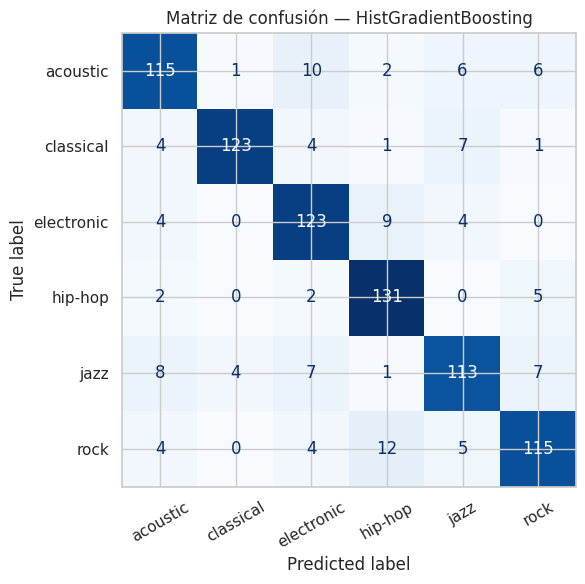

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 6))
cm = confusion_matrix(y_val, best_model.predict(X_val), labels=best_model.classes_)
disp = ConfusionMatrixDisplay(cm, display_labels=best_model.classes_)
disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
ax.set_title(f"Matriz de confusión — {best_name}")
plt.tight_layout()
plt.show()

HistGradientBoosting es el mejor modelo (F1-Macro 0.857 en validation). **classical** y **hip-hop** son las clases que mejor predice. Las confusiones más frecuentes son rock → hip-hop (12), acoustic → electronic (10) y electronic → hip-hop (9), y **jazz** es la clase con más errores repartidos (se confunde con acoustic, electronic y rock). En cambio pares muy distintos como classical/hip-hop practicamente no se confunden.

## 8. MAP@3 (Mean Average Precision at K=3)

F1-Macro exige acertar el género exacto en una única predicción. Pero Spotify es un sistema de recomendación que muestra listas de opciones, entonces tiene más valor que el género correcto esté dentro del top-3 y que acertar en el primer lugar valga más que en el tercero.

Para cada muestra calculamos la AP@K:

$$
AP@K = \begin{cases} \dfrac{1}{rank} & \text{si el género correcto está en el top-K, en la posición } rank \\ 0 & \text{si no está en el top-K} \end{cases}
$$

y MAP@K es el promedio sobre todas las muestras. Con K=3, acertar en 1er lugar vale 1, en 2do 0.5, en 3ro 0.33 y fuera del top-3 vale 0. Como hay una sola etiqueta correcta por canción, esto coincide con la definición general de MAP@K.

La métrica necesita probabilidades por clase (`predict_proba`), que los tres modelos exponen.

In [21]:
def average_precision_at_k(y_true, y_proba, classes, k=3):
    y_true = np.asarray(y_true)
    classes = np.asarray(classes)

    top_k_idx = np.argsort(-y_proba, axis=1)[:, :k]
    top_k_labels = classes[top_k_idx]

    ap = np.zeros(len(y_true))
    for rank in range(k):
        hit = (top_k_labels[:, rank] == y_true) & (ap == 0)
        ap[hit] = 1.0 / (rank + 1)
    return ap

def map_at_k(y_true, y_proba, classes, k=3):
    return average_precision_at_k(y_true, y_proba, classes, k).mean()

def map3_scorer(estimator, X, y):
    proba = estimator.predict_proba(X)
    return map_at_k(y, proba, estimator.classes_, k=3)

In [22]:
toy_classes = np.array(["a", "b", "c"])
toy_proba = np.array([
    [0.7, 0.2, 0.1],
    [0.1, 0.3, 0.6],
    [0.1, 0.8, 0.1],
])
toy_y = np.array(["a", "a", "z"])
print(average_precision_at_k(toy_y, toy_proba, toy_classes, k=3))
print("MAP@3:", map_at_k(toy_y, toy_proba, toy_classes, k=3))

[1.         0.33333333 0.        ]
MAP@3: 0.4444444444444444


### 8.1 Comparación con F1-Macro y MAP@3

In [23]:
comparison = []
for name, model in best_models.items():
    preds = model.predict(X_val)
    proba = model.predict_proba(X_val)
    f1 = f1_score(y_val, preds, average="macro")
    m3 = map_at_k(y_val, proba, model.classes_, k=3)
    comparison.append({"modelo": name, "F1_Macro": f1, "MAP@3": m3})

comparison_df = pd.DataFrame(comparison).sort_values("F1_Macro", ascending=False)
comparison_df

,modelo,F1_Macro,MAP@3
2,HistGradientBoosting,0.857147,0.908929
1,RandomForest,0.842565,0.899206
0,LogisticRegression,0.663155,0.779762


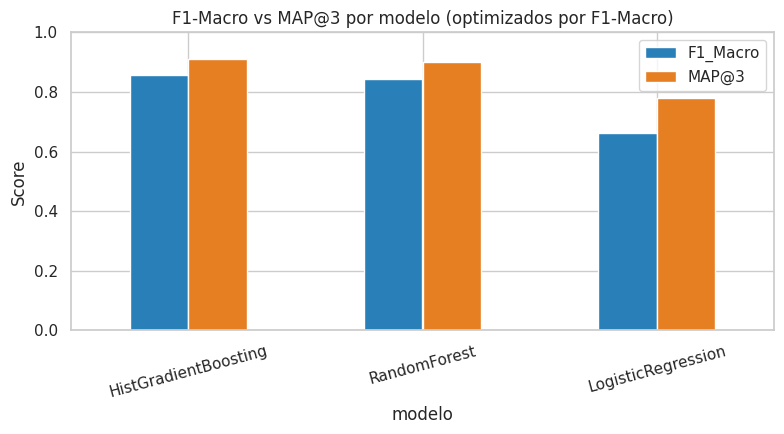

In [24]:
fig, ax = plt.subplots(figsize=(8, 4.5))
comparison_df.set_index("modelo")[["F1_Macro", "MAP@3"]].plot(
    kind="bar", ax=ax, color=["#2980b9", "#e67e22"]
)
ax.set_ylabel("Score")
ax.set_title("F1-Macro vs MAP@3 por modelo (optimizados por F1-Macro)")
ax.set_ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

MAP@3 es siempre mayor que F1-Macro porque es más fácil tener el género correcto en el top-3 que acertarlo en el top-1. El ranking entre modelos se mantiene igual con las dos métricas: HistGradientBoosting (0.909) > Random Forest (0.899) > Regresión Logística (0.780). Lo interesante es que la diferencia entre la Regresión Logística y los ensambles se achica con MAP@3 (de ~0.19 a ~0.13), o sea que el modelo lineal muchas veces tiene el género correcto en 2do o 3er lugar.

## 9. Optimizando directamente para MAP@3

El modelo que maximiza F1-Macro no necesariamente maximiza MAP@3, porque una métrica mira solo el top-1 y la otra el ranking del top-3. Para optimizar MAP@3 directamente usamos `map3_scorer` como `scoring` en la búsqueda de hiperparámetros de Random Forest.

In [25]:
rs_rf_map3 = RandomizedSearchCV(
    models["RandomForest"], param_dist_rf, n_iter=20,
    scoring=map3_scorer, cv=cv, n_jobs=-1,
    random_state=RANDOM_STATE, refit=True
)
rs_rf_map3.fit(X_train, y_train)

print("Mejor MAP@3 (CV):", rs_rf_map3.best_score_)
print("Mejores hiperparámetros:", rs_rf_map3.best_params_)

Mejor MAP@3 (CV): 0.8843253968253968
Mejores hiperparámetros: {'clf__n_estimators': 500, 'clf__min_samples_leaf': 2, 'clf__max_features': 0.5, 'clf__max_depth': 24}


In [26]:
model_f1opt = best_models["RandomForest"]
model_map3opt = rs_rf_map3.best_estimator_

rows = []
for label, model in [("RF optimizado por F1-Macro", model_f1opt),
                      ("RF optimizado por MAP@3", model_map3opt)]:
    preds = model.predict(X_val)
    proba = model.predict_proba(X_val)
    rows.append({
        "estrategia": label,
        "F1_Macro": f1_score(y_val, preds, average="macro"),
        "MAP@3": map_at_k(y_val, proba, model.classes_, k=3),
    })

tradeoff_df = pd.DataFrame(rows)
tradeoff_df

,estrategia,F1_Macro,MAP@3
0,RF optimizado por F1-Macro,0.842565,0.899206
1,RF optimizado por MAP@3,0.842565,0.899206


En nuestro caso la búsqueda por MAP@3 eligió **exactamente los mismos hiperparámetros** que la búsqueda por F1-Macro, así que los dos modelos dan los mismos scores. Esto indica que, dentro del espacio de hiperparámetros explorado, F1-Macro y MAP@3 están muy correlacionadas: el modelo que mejor ordena el top-1 también es el que mejor ordena el top-3, y no hizo falta sacrificar una métrica por la otra.

Otras formas de mejorar MAP@3 que se podrían probar:

- Calibrar las probabilidades (`CalibratedClassifierCV`) para que el orden del top-3 sea más confiable.
- Promediar las `predict_proba` de Random Forest y Boosting para tener un ranking más robusto.
- Ampliar el espacio de búsqueda (rangos más extremos, más iteraciones) o usar otros modelos, lo que podría hacer aparecer el trade-off entre las dos métricas.

## 10. ¿Qué métrica usar en cada caso de negocio?

**F1-Macro** tiene sentido cuando el género predicho se usa como **etiqueta única**, sin lugar a ambigüedad: por ejemplo catalogar automáticamente canciones nuevas en la base de datos, generar metadata para reportes por género, o alimentar otro modelo que espera una sola categoría. El promedio macro sirve cuando todos los géneros importan por igual, independientemente de cuántas canciones haya de cada uno.

**MAP@3** tiene sentido cuando al usuario se le muestra **una lista de opciones**: sugerencias de género para armar una playlist, filtros de descubrimiento ("quizás te interese: Jazz, Acoustic o Classical"), o asistir a un equipo de curaduría mostrándole las 3 categorías más probables. Ahí lo importante es que la opción correcta esté disponible y bien arriba en la lista.

**Otras métricas que podrían adecuarse mejor según el caso:**

- **Precision por clase**, si un falso positivo en un género puntual es costoso (por ejemplo por temas de licenciamiento).
- **Recall por clase**, si el objetivo es no perderse canciones de un género de nicho, aunque haya más falsos positivos.
- **Top-K accuracy con K más grande** (Top-5), si el producto muestra listas más largas.
- **Una matriz de costos propia**, si algunas confusiones son mucho más graves que otras (confundir rock con electronic puede ser aceptable, pero classical con hip-hop genera quejas de usuarios).
- **AUC-PR por clase**, si se necesita ajustar el threshold de decisión de cada género.

## 11. Entrenamiento final y generación del submission.csv

Reentrenamos el mejor pipeline (HistGradientBoosting con los hiperparámetros encontrados) sobre **todo** `train.csv`, ya que una vez elegido el modelo no tiene sentido desperdiciar el 20% de validation. El `ColumnTransformer` se reajusta sobre todo el train y después se aplica sobre `test.csv`.

In [27]:
FINAL_MODEL_NAME = best_name
final_pipeline = best_models[FINAL_MODEL_NAME]

X_full = train.drop(columns=DROP_COLS).copy()
X_full["explicit"] = X_full["explicit"].astype(int)
y_full = train[TARGET].copy()

final_pipeline.fit(X_full, y_full)

X_test = test.drop(columns=["Id"]).copy()
X_test["explicit"] = X_test["explicit"].astype(int)

test_preds = final_pipeline.predict(X_test)

submission = pd.DataFrame({"Id": test["Id"], "Expected": test_preds})
submission.to_csv("submission.csv", index=False)

print(f"Modelo final: {FINAL_MODEL_NAME}")
print(submission.head())
print("\nDistribución de predicciones en test:")
print(submission["Expected"].value_counts())

Modelo final: HistGradientBoosting
     Id    Expected
0  3793    acoustic
1  5701    acoustic
2  2721  electronic
3  4079     hip-hop
4   479  electronic

Distribución de predicciones en test:
Expected
rock          311
hip-hop       308
acoustic      306
classical     298
electronic    296
jazz          281
Name: count, dtype: int64


## 12. Conclusiones

- Los ensambles de árboles superan claramente al modelo lineal, lo que muestra que el problema tiene relaciones no lineales entre features. El mejor modelo fue **HistGradientBoosting** con F1-Macro ≈ 0.857 y MAP@3 ≈ 0.909 en validation.
- Las features que más separan los géneros son `acousticness`, `instrumentalness`, `energy`, `danceability` y `explicit`.
- El dataset tiene un techo de ruido por filas duplicadas con etiquetas distintas, así que un score perfecto no es alcanzable.
- Optimizar por MAP@3 no cambió el modelo elegido: en este problema ambas métricas estan muy alineadas.
- La métrica a usar depende del caso de negocio: F1-Macro para etiquetado único, MAP@3 para recomendaciones en forma de lista.